# Week 6 Recitation — SVD and Images 


**Today:** We use SVD to make a dog image with fewer patterns.

## 1. Load the image

“A color image has three layers: red, green, and blue. Each layer is a matrix.”

RGB: (200, 300, 3)
Red channel: (200, 300)


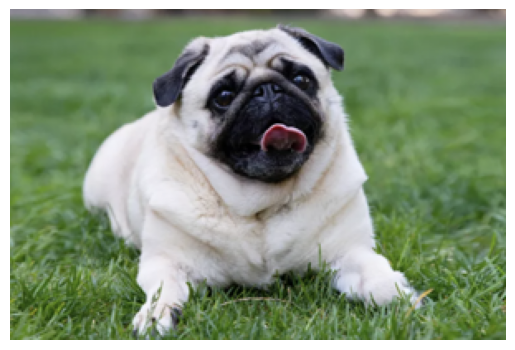

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import linalg
from pathlib import Path

# Keep dog.png in the same folder as this notebook.
image_path = Path("dog.png")
img = Image.open(image_path).convert("RGB").resize((300, 200))
rgb = np.asarray(img, dtype=float) / 255.0
A = rgb[:, :, 0]  # red channel
print("RGB:", rgb.shape)  # (200, 300, 3)
print("Red channel:", A.shape)  # (200, 300)
plt.imshow(rgb)
plt.axis("off")
plt.show()

“The first number is height, the second is width. `3` means three colors.”

## 2. What is SVD?

$A = U\,\mathrm{diag}(s)\,V^H$

“SVD breaks an image into simple patterns. The numbers in `s` tell us how important these patterns are. We keep the first `k` patterns.”

**Remember:** Bigger `k` = more detail.

## 3. Run SVD 

“We use one line of code to get `U`, `s`, and `Vh`. We do not need to calculate them by hand.”

In [8]:
U, s, Vh = linalg.svd(A, full_matrices=False)
print("U:", U.shape)    # (200, 200)
print("s:", s.shape)    # (200,)
print("Vh:", Vh.shape)  # (200, 300)

U: (200, 200)
s: (200,)
Vh: (200, 300)


“`s` is a list of numbers, not a matrix. `np.diag(s)` turns it into a diagonal matrix.”

## 4. Keep only k patterns 

“Let's keep only 10 patterns. Notice that the image size stays the same.”

- `U[:, :k]`: first `k` columns
- `s[:k]`: first `k` values
- `Vh[:k, :]`: first `k` rows
- `@`: matrix multiplication (not the same as `*`)

Original: (200, 300) New: (200, 300)


/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/728815338.py:2: RuntimeWarning: divide by zero encountered in matmul
  A_k = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/728815338.py:2: RuntimeWarning: overflow encountered in matmul
  A_k = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/728815338.py:2: RuntimeWarning: invalid value encountered in matmul
  A_k = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]


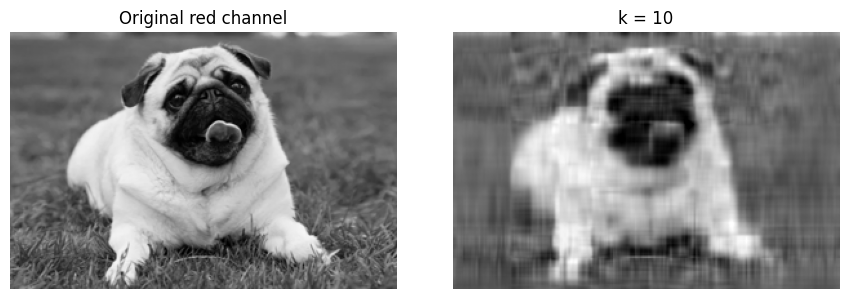

In [ ]:
k = 10
A_k = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
print("Original:", A.shape, "New:", A_k.shape)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].imshow(A, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original red channel")
ax[1].imshow(np.clip(A_k, 0, 1), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("k = 10")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

## 5. Color image: try different k 

“We do the same thing for red, green, and blue, then stack the three layers together. We do **not** add them.”

/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/854957445.py:6: RuntimeWarning: divide by zero encountered in matmul
  channels.append(Uc[:, :k] @ np.diag(sc[:k]) @ Vhc[:k, :])
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/854957445.py:6: RuntimeWarning: overflow encountered in matmul
  channels.append(Uc[:, :k] @ np.diag(sc[:k]) @ Vhc[:k, :])
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/854957445.py:6: RuntimeWarning: invalid value encountered in matmul
  channels.append(Uc[:, :k] @ np.diag(sc[:k]) @ Vhc[:k, :])


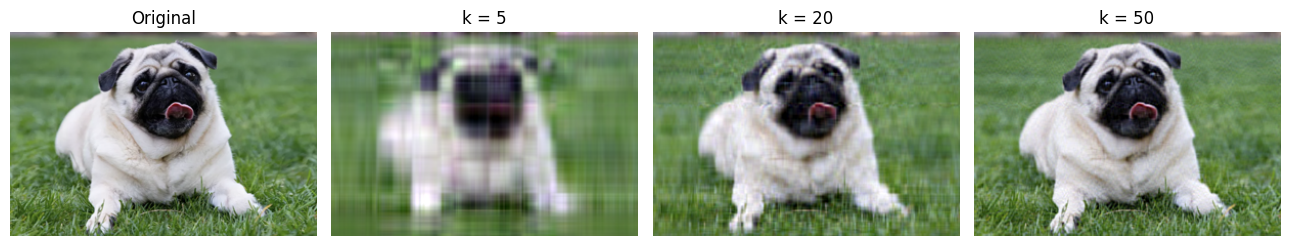

In [10]:
channel_svds = [linalg.svd(rgb[:, :, c], full_matrices=False) for c in range(3)]

def reconstruct_color(k):
    channels = []
    for Uc, sc, Vhc in channel_svds:
        channels.append(Uc[:, :k] @ np.diag(sc[:k]) @ Vhc[:k, :])
    return np.stack(channels, axis=2)  # (200, 300, 3)

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, picture, name in zip(
    axes,
    [rgb, reconstruct_color(5), reconstruct_color(20), reconstruct_color(50)],
    ["Original", "k = 5", "k = 20", "k = 50"]
):
    ax.imshow(np.clip(picture, 0, 1))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Ask:** “Which one looks clearer?”  **Answer:** “Usually `k = 50`. Larger `k` keeps more details.”

## 6. Image quality and storage 

“Bigger `k` means better quality, but we store more numbers.”

For one 200 × 300 color channel:
- Original: `200 * 300 = 60,000` numbers
- Rank-20: `20 * (200 + 300 + 1) = 10,020` numbers

These are **number counts**, not actual JPEG or PNG file sizes.

**MSE** measures the average squared difference. Smaller MSE is better.

In [11]:
for k in [5, 20]:
    result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
    mse = np.mean((A - result) ** 2)  # use values before clipping
    stored = k * (200 + 300 + 1)
    print(f"k={k}: shape={result.shape}, MSE={mse:.6f}, stored values={stored}")

k=5: shape=(200, 300), MSE=0.009719, stored values=2505
k=20: shape=(200, 300), MSE=0.002177, stored values=10020


/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/4047150764.py:2: RuntimeWarning: divide by zero encountered in matmul
  result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/4047150764.py:2: RuntimeWarning: overflow encountered in matmul
  result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/4047150764.py:2: RuntimeWarning: invalid value encountered in matmul
  result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]


## 7. Quick student exercise 

“Work with a partner. Change `k` from 5 to 20 for the red channel.”

1. Which output has smaller MSE?
2. Do their shapes change?
3. Which one stores more numbers?



In [12]:
# Quick check / solution: students can change the k values.
for k in [5, 20]:
    red_result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
    print(f"k={k}: shape={red_result.shape}, MSE={np.mean((A - red_result)**2):.6f}")

/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/1891170799.py:3: RuntimeWarning: divide by zero encountered in matmul
  red_result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/1891170799.py:3: RuntimeWarning: overflow encountered in matmul
  red_result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]
/var/folders/z4/cyv0pfhs0sb3531vj7glg5g00000gn/T/ipykernel_19566/1891170799.py:3: RuntimeWarning: invalid value encountered in matmul
  red_result = U[:, :k] @ np.diag(s[:k]) @ Vh[:k, :]


k=5: shape=(200, 300), MSE=0.009719
k=20: shape=(200, 300), MSE=0.002177


## 8. Wrap up 

“Three things to remember: SVD finds patterns. `k` controls how many we keep. Larger `k` usually looks better, but uses more storage.”

**Final quick check:** Does `k = 5` mean a 5 × 5 picture? **No.** The image stays 200 × 300.

*Optional, only if asked:* With `k = 200`, we recover the red channel up to tiny rounding error. For a real-valued image, `Vh` is the transposed right-factor matrix. The unclipped reconstruction MSE cannot increase when `k` grows.